# Exercice 7 - Apprentissage non supervisé : la ressemblance visuelle retrouve-t-elle les espèces ?

## Le jeu de données :

Je reprends le même corpus qu'à l'exercice 6 : un sous-ensemble équilibré d'Animals-10, soit 10 000 photographies d'animaux collectées sur le web, 1 000 par espèce pour dix espèces (araignée, chat, cheval, chien, écureuil, éléphant, mouton, papillon, poule, vache). Les images sont hétérogènes en taille, cadrage, fond et éclairage, et converties en RGB au chargement. Utiliser le même corpus que l'exercice 6 permet de comparer directement ce que la supervision apporte par rapport à une approche purement non supervisée.

URL du jeu de données : https://www.kaggle.com/datasets/alessiocorrado99/animals10

## Le problème : un problème non supervisé

Contrairement à l'exercice 6, je n'utilise pas les étiquettes pour l'apprentissage. La question posée est la suivante : en regroupant les images uniquement d'après leur ressemblance visuelle, retrouve-t-on spontanément les espèces ? Je partitionne donc les 10 000 images en groupes à partir des seules caractéristiques visuelles. Les véritables espèces ne servent qu'après coup, pour l'évaluation : elles mesurent dans quelle mesure les groupes trouvés coïncident avec les espèces réelles. Répondre à cette question dit si une photothèque animalière peut s'organiser toute seule, sans annotation manuelle.

Les caractéristiques sont exactement celles de l'exercice 6 (histogramme de couleur RGB en 48 dimensions et HOG en 1 764 dimensions, soit 1 812 dimensions par image), rechargées depuis le cache partagé.

## La chaîne de traitement et les métriques :

1. Standardisation des caractéristiques, indispensable car histogramme et HOG vivent sur des échelles différentes.
2. Réduction de dimension par PCA en conservant 95 % de la variance, ce qui débruite et accélère la suite.
3. Clustering dans l'espace réduit avec deux méthodes : k-means à 10 clusters, et un mélange de gaussiennes à 10 composantes qui autorise des clusters de formes et tailles différentes. Le k-means regroupe selon la distance euclidienne dans cet espace standardisé puis réduit par PCA ; la standardisation préalable rend cette distance pertinente, en évitant qu'une caractéristique de grande amplitude domine les autres.
4. Visualisation en deux dimensions par t-SNE, une projection non vue en cours : elle place les points en 2D en préservant surtout les voisinages locaux, ce qui la rend adaptée à la visualisation de structure (au prix de déformations globales).
5. Évaluation. L'accuracy est inutilisable en clustering, les numéros de groupes étant arbitraires, je combine donc deux métriques externes qui comparent les groupes aux espèces indépendamment de l'étiquetage des clusters, l'ARI (accord entre deux partitions par comptage des paires bien regroupées, corrigé du hasard, 0 pour l'aléatoire et 1 pour l'identité) et la NMI (information partagée entre les deux partitions, normalisée entre 0 et 1), avec une métrique interne, la silhouette (compacité et séparation des clusters, calculées à partir des seules distances, entre -1 et 1). Le cours évalue le k-means par l'inertie ; l'ARI, la NMI et la projection t-SNE utilisée plus bas ne sont pas au programme, d'où leur brève description ici.

caractéristiques : (10000, 1812), 10 classes équilibrées [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


PCA : 527 composantes retenues pour 95 % de variance (sur 1812 dimensions)


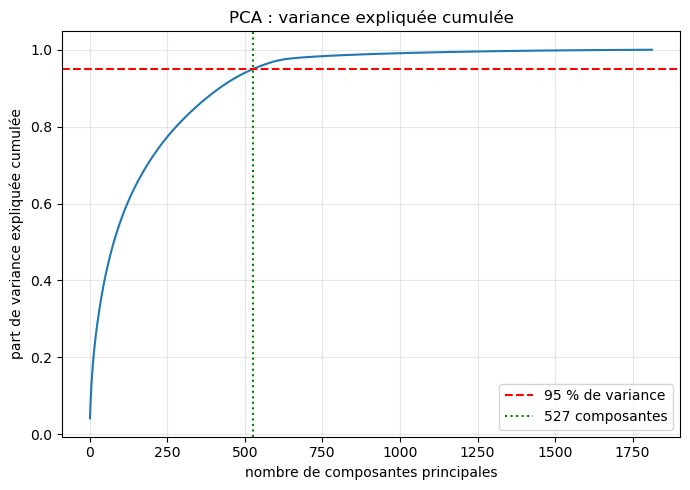

In [1]:
%matplotlib inline
# On recharge les caractéristiques mises en cache par l'exercice 6, puis on
# standardise et on réduit la dimension par PCA en gardant 95 % de la variance.
from pathlib import Path

import matplotlib.pyplot as plt
import json

import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

CACHE_DIR = Path.cwd().parent / "data" / "animals10_features"
DATA_DIR = Path.cwd().parent / "data" / "animals10_1k"
RANDOM_STATE = 42

X = np.load(CACHE_DIR / "X_classic.npy")
y = np.load(CACHE_DIR / "y.npy")
# noms de classes lus depuis le cache (produit par l'exercice 6), repli sur le dossier d'images
classes_json = CACHE_DIR / "classes.json"
if classes_json.exists():
    classes = json.loads(classes_json.read_text())["classes"]
else:
    classes = sorted(d.name for d in DATA_DIR.iterdir() if d.is_dir())
print(f"caractéristiques : {X.shape}, {len(classes)} classes équilibrées {np.bincount(y)}")

Xs = StandardScaler().fit_transform(X)
pca_complete = PCA(random_state=RANDOM_STATE).fit(Xs)
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(Xs).astype(np.float64)
print(f"PCA : {X_pca.shape[1]} composantes retenues pour 95 % de variance (sur {Xs.shape[1]} dimensions)")

cumul = np.cumsum(pca_complete.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(np.arange(1, len(cumul) + 1), cumul, lw=1.5)
ax.axhline(0.95, color="red", ls="--", label="95 % de variance")
ax.axvline(X_pca.shape[1], color="green", ls=":", label=f"{X_pca.shape[1]} composantes")
ax.set_xlabel("nombre de composantes principales")
ax.set_ylabel("part de variance expliquée cumulée")
ax.set_title("PCA : variance expliquée cumulée")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

La montée très progressive de la courbe (527 composantes pour atteindre 95 %) montre que l'information des descripteurs est diffuse, aucune direction ne domine. C'est un premier indice que la structure de ces caractéristiques est faible.

In [2]:
# clustering dans l'espace PCA avec k-means et un mélange de gaussiennes,
# puis évaluation contre les vraies espèces (qui ne servent qu'ici)
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.mixture import GaussianMixture

km = KMeans(n_clusters=len(classes), n_init=10, random_state=RANDOM_STATE)
labels_km = km.fit_predict(X_pca)

gmm = GaussianMixture(n_components=len(classes), covariance_type="full", reg_covar=1e-4, random_state=RANDOM_STATE)
labels_gmm = gmm.fit_predict(X_pca)

print(f"{'méthode':<18}{'ARI':>9}{'NMI':>9}{'silhouette':>12}")
for nom, labels in [("KMeans", labels_km), ("GaussianMixture", labels_gmm)]:
    ari = adjusted_rand_score(y, labels)
    nmi = normalized_mutual_info_score(y, labels)
    sil = silhouette_score(X_pca, labels)
    print(f"{nom:<18}{ari:>9.4f}{nmi:>9.4f}{sil:>12.4f}")

méthode                 ARI      NMI  silhouette


KMeans               0.0389   0.0921     -0.0011


GaussianMixture      0.0389   0.0921     -0.0011


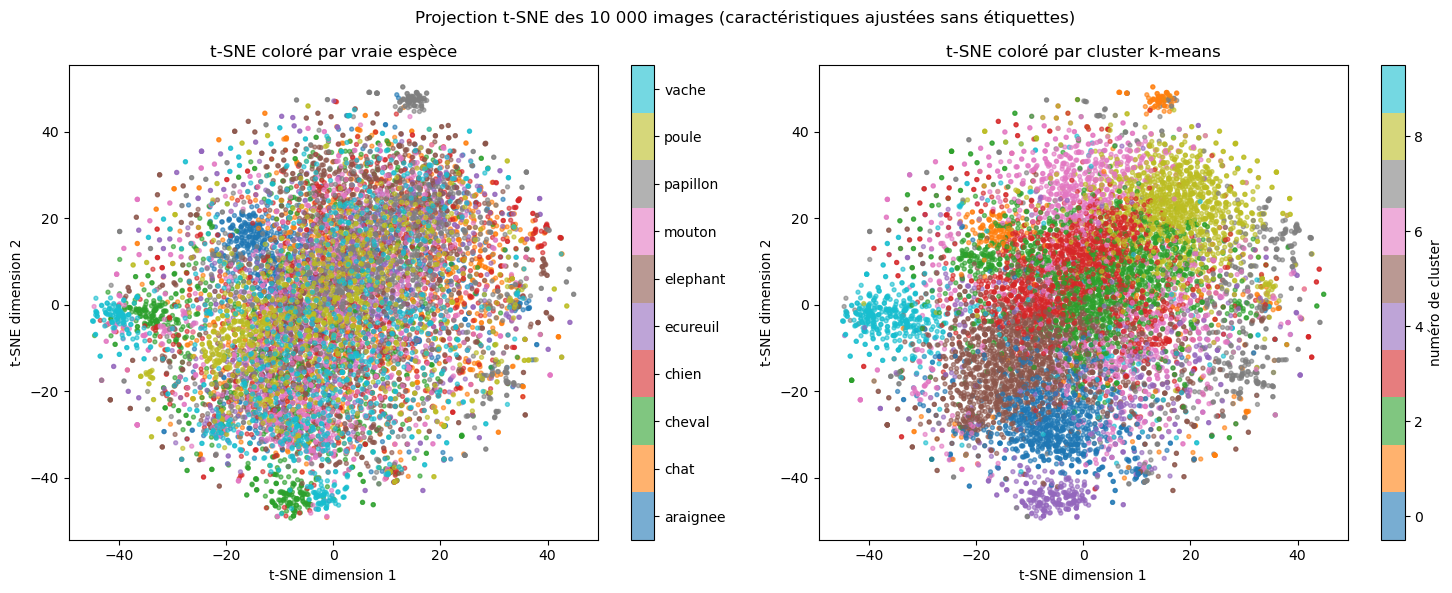

In [3]:
# projection t-SNE en 2D, colorée par vraie espèce puis par cluster k-means
from sklearn.manifold import TSNE

tsne2d = TSNE(n_components=2, init="pca", perplexity=30, random_state=RANDOM_STATE).fit_transform(X_pca)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sc0 = axes[0].scatter(tsne2d[:, 0], tsne2d[:, 1], c=y, s=8, alpha=0.6, cmap="tab10", vmin=-0.5, vmax=9.5)
axes[0].set_title("t-SNE coloré par vraie espèce")
axes[0].set_xlabel("t-SNE dimension 1")
axes[0].set_ylabel("t-SNE dimension 2")
cbar0 = fig.colorbar(sc0, ax=axes[0], ticks=range(10))
cbar0.ax.set_yticklabels(classes)
sc1 = axes[1].scatter(tsne2d[:, 0], tsne2d[:, 1], c=labels_km, s=8, alpha=0.6, cmap="tab10", vmin=-0.5, vmax=9.5)
axes[1].set_title("t-SNE coloré par cluster k-means")
axes[1].set_xlabel("t-SNE dimension 1")
axes[1].set_ylabel("t-SNE dimension 2")
fig.colorbar(sc1, ax=axes[1], label="numéro de cluster")
fig.suptitle("Projection t-SNE des 10 000 images (caractéristiques ajustées sans étiquettes)")
fig.tight_layout()
plt.show()

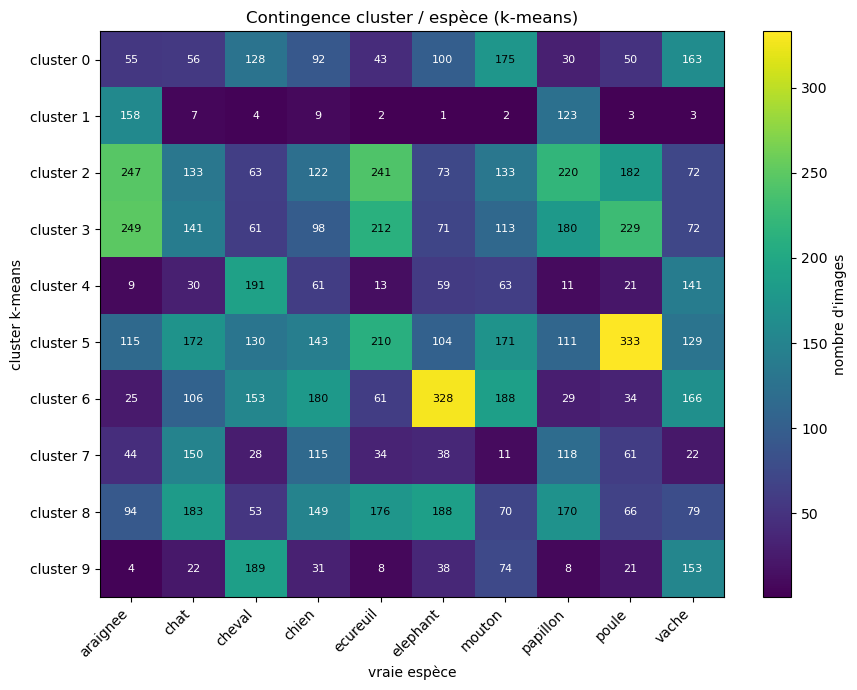

In [4]:
# table de contingence : chaque cluster k-means contient combien de chaque espèce ?
contingence = np.zeros((10, 10), dtype=int)
for vrai, predit in zip(y, labels_km):
    contingence[predit, vrai] += 1

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(contingence, cmap="viridis", aspect="auto")
ax.set_xticks(range(10), classes, rotation=45, ha="right")
ax.set_yticks(range(10), [f"cluster {i}" for i in range(10)])
ax.set_xlabel("vraie espèce")
ax.set_ylabel("cluster k-means")
ax.set_title("Contingence cluster / espèce (k-means)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, contingence[i, j], ha="center", va="center", color="white" if contingence[i, j] < contingence.max() / 2 else "black", fontsize=8)
fig.colorbar(im, ax=ax, label="nombre d'images")
fig.tight_layout()
plt.show()

## Résultats et discussion :

L'alignement entre clusters et espèces est quasi nul : ARI de 0.0389 et NMI de 0.0921 pour les deux méthodes, et une silhouette de -0.0011, quasi nulle, qui indique des clusters ni compacts ni séparés. Les deux méthodes donnent d'ailleurs des métriques identiques : dans cet espace de grande dimension, le mélange de gaussiennes ne s'écarte quasiment pas de la partition k-means, la structure gaussienne supplémentaire n'apporte rien, ce qui est un résultat en soi. La raison est mécanique : GaussianMixture s'initialise par défaut sur une partition k-means (init_params='kmeans'), et en dimension 527 l'algorithme EM converge en quelques itérations sans quitter cette solution.

La projection t-SNE explique pourquoi. Côté vraies espèces, on observe un grand continuum mélangé, avec seulement quelques îlots purs, des araignées en gros plan sur fond uni et des papillons sur fond uniforme. Côté clusters, k-means découpe ce continuum en zones arbitraires. La table de contingence précise la lecture : la plupart des clusters mélangent toutes les espèces, avec trois exceptions lisibles, un cluster araignée et papillon (158 et 123 images, gros plans sur fond uni), un cluster dominé par les éléphants (328 images, tons gris) et un dominé par les poules (333 images, tons chauds). Deux clusters regroupent chevaux et vaches (191 et 141 images pour l'un, 189 et 153 pour l'autre), cohérent avec des fonds de prairie similaires.

La ressemblance visuelle mesurée par ces descripteurs regroupe donc par palette et par fond, pas par espèce. Ce résultat négatif est cohérent avec le plafond supervisé de l'exercice 6 (0.4900 d'accuracy test avec les mêmes caractéristiques) : le facteur limitant est la représentation, pas l'algorithme de clustering.

## Conclusion :

Sur les mêmes 10 000 images et les mêmes 1 812 descripteurs que l'exercice 6, le clustering non supervisé (k-means et mélange de gaussiennes sur PCA à 95 % de variance) ne reconstruit pas les espèces : ARI 0.0389, NMI 0.0921, silhouette -0.0011. Les groupes qui émergent correspondent à des conditions de prise de vue (fond uni, prairie, dominante de couleur) plutôt qu'à la sémantique des animaux. La question posée reçoit donc une réponse claire et négative : avec des descripteurs artisanaux, la ressemblance visuelle ne retrouve pas les espèces, et une photothèque ne s'organiserait pas toute seule sur cette base. Le même pipeline appliqué à des représentations apprises (embeddings d'un réseau pré-entraîné) serait l'étape suivante naturelle, l'exercice 6 ayant montré que c'est la représentation qui plafonne.